# Лабораторная работа №6. Использование внешних библиотек в ассемблере

**Выполнил:** Рулев Константин Александрович  
**Вариант:** 16

**Цель:** создать движение курсора по спирали с цветным следом.

Отчёт содержит исходники и результаты. Для повторного запуска в Google Colab выберите среду CPU и выполните все ячейки. Программа проверена в Linux x86-64; для Colab подготовлен запуск в отдельном терминале внутри среды.

## 1. Данные варианта

Движение **№6** — спираль из центра. Цвета — **белый и жёлтый**. Клавиша **p** завершает программу, **f** меняет скорость: 80 → 40 → 20 → 160 → 80 мс.

In [1]:
import random
r = random.Random(16)
colors = ['COLOR_BLACK', 'COLOR_RED', 'COLOR_GREEN', 'COLOR_YELLOW', 'COLOR_BLUE', 'COLOR_MAGENTA', 'COLOR_CYAN', 'COLOR_WHITE']
buttons = list('qwertyuiopasdfghjklzxcvbnm')
print('Движение:', r.sample(range(1, 9), 1)[0])
print('Цвета:', r.sample(colors, 2))
print('Выход, скорость:', r.sample(buttons, 2))


Движение: 6
Цвета: ['COLOR_WHITE', 'COLOR_YELLOW']
Выход, скорость: ['p', 'f']


## 2. Алгоритм

Курсор идёт вверх, вправо, вниз и влево. Длины сторон: 1, 1, 2, 2, 3, 3 и так далее. Если следующий шаг выходит за границу, движение снова начинается из центра другим цветом. Старый след остаётся на экране.

Последний столбец оставлен пустым, чтобы терминал не прокручивался при записи в правый нижний угол. При изменении размера окна спираль начинается заново.

## 3. Подготовка среды

In [2]:
import os
import platform
import shutil
import subprocess
import sys
from pathlib import Path

assert platform.system() == 'Linux' and platform.machine() in ('x86_64', 'amd64'), 'Нужна среда Linux x86-64'
prefix = [] if os.geteuid() == 0 else ['sudo']
if not all(shutil.which(name) for name in ['fasm', 'gcc', 'ld', 'make']) or not Path('/usr/include/ncurses.h').exists():
    subprocess.run(prefix + ['apt-get', 'update', '-qq'], check=True)
    subprocess.run(prefix + ['apt-get', 'install', '-y', '-qq', 'fasm', 'gcc', 'binutils', 'make', 'libncurses-dev'], check=True)
try:
    import pyte
    from PIL import Image
except ImportError:
    subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', 'pyte', 'pillow'], check=True)
if not Path('/usr/share/fonts/truetype/dejavu/DejaVuSansMono.ttf').exists():
    subprocess.run(prefix + ['apt-get', 'update', '-qq'], check=True)
    subprocess.run(prefix + ['apt-get', 'install', '-y', '-qq', 'fonts-dejavu-core'], check=True)
work = (Path('/content') if Path('/content').exists() else Path('/tmp')) / 'rulev_variant16' / 'Lab_6'
work.mkdir(parents=True, exist_ok=True)
os.chdir(work)
print('Среда готова')


Среда готова


## 4. Исходный код

`initscr` включает работу с экраном, `move` перемещает курсор, `addch` оставляет след. `getch` читает клавишу, `timeout` задаёт паузу, `endwin` восстанавливает терминал.

### Rulev.asm

In [3]:
%%writefile Rulev.asm
format ELF64
public _start

extrn initscr
extrn start_color
extrn init_pair
extrn noecho
extrn cbreak
extrn stdscr
extrn getmaxx
extrn getmaxy
extrn clear
extrn move
extrn addch
extrn refresh
extrn timeout
extrn getch
extrn endwin
extrn exit

section '.data' writable
    width dd 0
    height dd 0
    new_width dd 0
    x dd 0
    y dd 0
    direction dd 0
    length dd 1
    remaining dd 1
    turns dd 0
    palette dd 100h
    delay dd 80
    step_x dd 0, 1, 0, -1
    step_y dd -1, 0, 1, 0

section '.text' executable
_start:
    call initscr
    test rax, rax
    jz failed
    call start_color
    cmp eax, -1
    je screen_failed
    mov edi, 1
    mov esi, 7
    xor edx, edx
    call init_pair
    cmp eax, -1
    je screen_failed
    mov edi, 2
    mov esi, 3
    xor edx, edx
    call init_pair
    cmp eax, -1
    je screen_failed
    call noecho
    call cbreak

draw:
    mov rdi, [stdscr]
    call getmaxx
    dec eax
    mov [new_width], eax
    mov rdi, [stdscr]
    call getmaxy
    cmp eax, 1
    jl screen_failed
    cmp dword [new_width], 1
    jl screen_failed
    cmp eax, [height]
    jne resized
    mov edx, [new_width]
    cmp edx, [width]
    je paint
resized:
    mov [height], eax
    mov eax, [new_width]
    mov [width], eax
    call clear
    call reset
paint:
    mov edi, [y]
    mov esi, [x]
    call move
    mov edi, [palette]
    or edi, '#'
    call addch
    mov edi, [y]
    mov esi, [x]
    call move
    call refresh
    mov edi, [delay]
    call timeout
    call getch
    cmp eax, 'p'
    je done
    cmp eax, 'f'
    jne advance
    shr dword [delay], 1
    cmp dword [delay], 20
    jge advance
    mov dword [delay], 160
advance:
    mov ecx, [direction]
    mov eax, [x]
    add eax, [step_x + rcx * 4]
    mov edx, [y]
    add edx, [step_y + rcx * 4]
    cmp eax, 0
    jl again
    cmp eax, [width]
    jge again
    cmp edx, 0
    jl again
    cmp edx, [height]
    jge again
    mov [x], eax
    mov [y], edx
    dec dword [remaining]
    jnz draw
    inc dword [direction]
    and dword [direction], 3
    inc dword [turns]
    cmp dword [turns], 2
    jne next_side
    mov dword [turns], 0
    inc dword [length]
next_side:
    mov eax, [length]
    mov [remaining], eax
    jmp draw
again:
    xor dword [palette], 300h
    call reset
    jmp draw

reset:
    mov eax, [width]
    dec eax
    shr eax, 1
    mov [x], eax
    mov eax, [height]
    shr eax, 1
    mov [y], eax
    mov dword [direction], 0
    mov dword [length], 1
    mov dword [remaining], 1
    mov dword [turns], 0
    ret

done:
    call endwin
    xor edi, edi
    call exit
screen_failed:
    call endwin
failed:
    mov edi, 1
    call exit


Writing Rulev.asm


### Makefile

In [4]:
%%writefile Makefile
.PHONY: all check run clean

all: build/Rulev

build:
	mkdir -p build

build/Rulev.o: Rulev.asm | build
	fasm $< $@

build/Rulev: build/Rulev.o
	ld -z noexecstack $< -lc -lncurses -dynamic-linker /lib64/ld-linux-x86-64.so.2 -o $@

build/check: build/Rulev.o mock.c
	gcc -Wall -Wextra -Werror -nostartfiles -no-pie -Wl,-z,noexecstack $^ -o $@

check: all build/check
	python3 check.py

run: all
	TERM=xterm-256color ./build/Rulev

clean:
	rm -rf build


Writing Makefile


## 5. Проверка

Проверка запускает тот же ASM-код с тестовыми функциями вместо экрана. Сравниваются координаты спирали, цвета, скорость, выход и изменение размеров окна.

### mock.c

In [5]:
%%writefile mock.c
#include <stdio.h>
#include <stdlib.h>

void *stdscr = (void *)1;
static int width, height, count, position_x, position_y, draws;

void *initscr(void) {
    width = atoi(getenv("COLS_TEST"));
    height = atoi(getenv("ROWS_TEST"));
    draws = atoi(getenv("DRAWS_TEST"));
    return stdscr;
}
int start_color(void) { return 0; }
int noecho(void) { return 0; }
int cbreak(void) { return 0; }
int getmaxx(void *window) { (void)window; return width; }
int getmaxy(void *window) { (void)window; return height; }
int clear(void) { puts("clear"); return 0; }
int init_pair(short pair, short front, short back) {
    printf("pair %d %d %d\n", pair, front, back);
    return 0;
}
int move(int y, int x) {
    position_x = x;
    position_y = y;
    return 0;
}
int addch(unsigned int value) {
    printf("draw %d %d %u\n", position_x, position_y, value);
    ++count;
    return 0;
}
int refresh(void) { return 0; }
void timeout(int delay) { printf("delay %d\n", delay); }
int getch(void) {
    if (count >= draws) return 'p';
    if (getenv("RESIZE_TEST") && count == 2) {
        width = 8;
        height = 7;
    }
    if (getenv("SPEED_TEST") && count <= 4) return 'f';
    return -1;
}
int endwin(void) { puts("endwin"); return 0; }


Writing mock.c


### check.py

In [6]:
%%writefile check.py
import os
import subprocess


def run(cols, rows, draws, **extra):
    env = dict(os.environ, COLS_TEST=str(cols), ROWS_TEST=str(rows),
               DRAWS_TEST=str(draws), **extra)
    result = subprocess.run(['./build/check'], env=env, text=True,
                            capture_output=True, timeout=5, check=True)
    lines = result.stdout.splitlines()
    assert lines[:2] == ['pair 1 7 0', 'pair 2 3 0']
    assert lines[-1] == 'endwin'
    points = [tuple(map(int, line.split()[1:])) for line in lines
              if line.startswith('draw ')]
    delays = [int(line.split()[1]) for line in lines if line.startswith('delay ')]
    return points, delays, lines


def expected(width, height):
    x, y = (width - 1) // 2, height // 2
    points = [(x, y)]
    for length in range(1, 2 * max(width, height) + 1):
        directions = [(0, -1), (1, 0)] if length % 2 else [(0, 1), (-1, 0)]
        for dx, dy in directions:
            for _ in range(length):
                x, y = x + dx, y + dy
                if not (0 <= x < width and 0 <= y < height):
                    return points
                points.append((x, y))


total = 0
for cols, rows in [(6, 5), (8, 7), (14, 7), (7, 4), (2, 1), (2, 7), (8, 1)]:
    path = expected(cols - 1, rows)
    points, delays, _ = run(cols, rows, 2 * len(path) + 1)
    wanted = [(x, y, ord('#') | color) for color in (0x100, 0x200)
              for x, y in path] + [(path[0][0], path[0][1], ord('#') | 0x100)]
    assert points == wanted, (cols, rows, points, wanted)
    assert len(set(path)) == len(path)
    assert delays == [80] * len(points)
    total += 1

points, delays, _ = run(6, 5, 6, SPEED_TEST='1')
assert delays == [80, 40, 20, 160, 80, 80], delays
total += 1
points, _, lines = run(6, 5, 6, RESIZE_TEST='1')
assert [(x, y) for x, y, _ in points[2:]] == expected(7, 7)[:4]
assert lines.count('clear') == 2
total += 1
print(f'Проверки движения, цветов, скорости, размеров окна и выхода: {total} из {total}.')


Writing check.py


In [7]:
%%bash
set -e
make check


mkdir -p build
fasm Rulev.asm build/Rulev.o
flat assembler  version 1.73.32  (16384 kilobytes memory)
3 passes, 3288 bytes.
ld -z noexecstack build/Rulev.o -lc -lncurses -dynamic-linker /lib64/ld-linux-x86-64.so.2 -o build/Rulev
gcc -Wall -Wextra -Werror -nostartfiles -no-pie -Wl,-z,noexecstack build/Rulev.o mock.c -o build/check
python3 check.py
Проверки движения, цветов, скорости, размеров окна и выхода: 9 из 9.


## 6. Результаты работы

Обычная ячейка Colab не принимает клавиши как терминал. Следующая программа открывает терминал, запускает ncurses, нажимает **f**, **f**, затем **p** и сохраняет кадры фактического вывода.

В обычном терминале программа запускается командой `make run`.

In [8]:
%%writefile capture.py
from pathlib import Path
import codecs
import fcntl
import os
import pty
import select
import struct
import subprocess
import termios
import time
import pyte
from PIL import Image, ImageDraw, ImageFont


def save_frame(screen, path):
    cell_w, cell_h = 18, 26
    picture = Image.new('RGB', (screen.columns * cell_w + 32,
                                screen.lines * cell_h + 32), '#111318')
    pen = ImageDraw.Draw(picture)
    font = ImageFont.truetype('/usr/share/fonts/truetype/dejavu/DejaVuSansMono.ttf', 21)
    colors = {'white': '#f2f2f2', 'brown': '#e5c74c', 'yellow': '#e5c74c',
              'default': '#f2f2f2', 'black': '#111318'}
    for row in range(screen.lines):
        for col in range(screen.columns):
            char = screen.buffer[row][col]
            pen.text((16 + col * cell_w, 16 + row * cell_h), char.data,
                     font=font, fill=colors.get(char.fg, char.fg))
    picture.save(path)


out = Path('evidence')
out.mkdir(exist_ok=True)
master, slave = pty.openpty()
fcntl.ioctl(slave, termios.TIOCSWINSZ, struct.pack('HHHH', 9, 12, 0, 0))
before = termios.tcgetattr(slave)
screen = pyte.Screen(12, 9)
stream = pyte.Stream(screen)
decoder = codecs.getincrementaldecoder('utf-8')('replace')
proc = subprocess.Popen(['./build/Rulev'], stdin=slave, stdout=slave, stderr=slave,
                        env=dict(os.environ, TERM='xterm-256color'))
raw = bytearray()
started = time.monotonic()
sent = 0
white_saved = yellow_saved = False
quit_sent = False
try:
    while time.monotonic() - started < 15:
        elapsed = time.monotonic() - started
        if sent < 2 and elapsed > 0.15 + sent * 0.18:
            os.write(master, b'f')
            sent += 1
        if select.select([master], [], [], 0.02)[0]:
            data = os.read(master, 65536)
            raw.extend(data)
            stream.feed(decoder.decode(data))
        chars = [screen.buffer[y][x] for y in range(9) for x in range(12)]
        white = sum(c.data == '#' and c.fg == 'white' for c in chars)
        yellow = sum(c.data == '#' and c.fg in ('brown', 'yellow') for c in chars)
        if not white_saved and white >= 45 and yellow == 0:
            save_frame(screen, out / 'white.png')
            white_saved = True
        if white_saved and not yellow_saved and yellow >= 30 and white > 0:
            save_frame(screen, out / 'yellow.png')
            yellow_saved = True
            os.write(master, b'p')
            quit_sent = True
        if proc.poll() is not None:
            break
    if proc.poll() is None:
        raise RuntimeError('Программа не завершилась за 15 секунд')
    assert proc.returncode == 0
    assert white_saved and yellow_saved and quit_sent
    assert termios.tcgetattr(slave) == before
finally:
    if proc.poll() is None:
        proc.kill()
        proc.wait()
    os.close(master)
    os.close(slave)
(out / 'terminal.ansi').write_bytes(raw)
print('Программа запущена с ncurses в терминале 12 × 9.')
print('Нажаты f, f, p. Сохранены белый и жёлтый следы.')
print('Выход: код 0. Настройки терминала восстановлены.')


Writing capture.py


In [9]:
%%bash
set -e
python3 capture.py


Программа запущена с ncurses в терминале 12 × 9.
Нажаты f, f, p. Сохранены белый и жёлтый следы.
Выход: код 0. Настройки терминала восстановлены.


### Первый проход — белый след

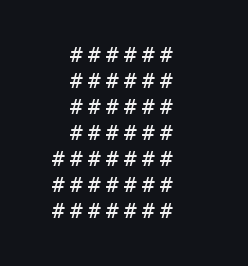

In [10]:
from IPython.display import display, Image
display(Image(filename='evidence/white.png'))


### Второй проход — жёлтый след

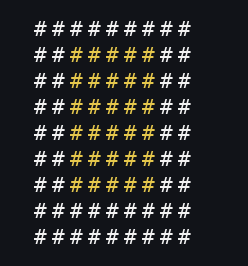

In [11]:
display(Image(filename='evidence/yellow.png'))


## Вывод

Создана программа движения по спирали. Цвет меняется при новом проходе. Клавиша **f** регулирует скорость, **p** завершает работу. Проверены движение, цвета и работа с настоящим терминалом.